# Supplementary Figure S8. Backbone validation, conformational context, and sugar-pucker relationships

In [1]:
import json
from collections import Counter
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.colors import Normalize

def _root() -> Path:
    here = Path.cwd().resolve()
    for base in [here, *here.parents]:
        if (base / "data").is_dir() and (base / "notebooks").is_dir():
            return base
    raise RuntimeError("run this from inside the analysis repo")

ROOT = _root()
data_file = lambda rel: ROOT / "data" / rel
_json = lambda rel: json.loads(data_file(rel).read_text())

def save(fig, rel):
    path = ROOT / rel
    path.parent.mkdir(parents=True, exist_ok=True)
    fig.savefig(path)
    return path

plt.rcParams.update({
    "figure.dpi": 130, "savefig.dpi": 300, "savefig.bbox": "tight",
    "font.family": "sans-serif",
    "font.sans-serif": ["Arial", "Helvetica Neue", "Helvetica", "DejaVu Sans"],
    "font.size": 8.5, "axes.labelsize": 9, "axes.titlesize": 9,
    "xtick.labelsize": 8, "ytick.labelsize": 8, "legend.fontsize": 8,
    "axes.linewidth": 0.8, "xtick.major.width": 0.8, "ytick.major.width": 0.8,
    "xtick.direction": "out", "ytick.direction": "out",
    "axes.grid": False, "legend.frameon": False,
    "pdf.fonttype": 42, "ps.fonttype": 42,
})
BLUE, ORANGE, GREEN, RED, GREY = "#4C72B0", "#DD8452", "#55A868", "#C44E52", "0.55"
POINT_FACE, POINT_EDGE, FIT = "#C9C9C9", "0.15", "#111111"

CUT = 80.0

LW = ["cWW", "tWW", "cWH", "tWH", "cWS", "tWS", "cHH", "tHH", "cHS", "tHS", "cSS", "tSS"]
TOOLS = ["parse", "fr3d", "rnaview", "barnaba", "rnapolis", "bpnet"]
TOOL_LABELS = ["FastRNA", "FR3D", "RNAView", "barnaba", "RNApolis", "BPNET"]

def finish(ax):
    for side in ("top", "right", "bottom", "left"):
        ax.spines[side].set_visible(True)
        ax.spines[side].set_linewidth(0.8)
    ax.grid(False)
    ax.tick_params(direction="out", width=0.8, length=3.5)
    return ax

def letter(fig, ax, s, dx=-0.030, dy=0.012):
    box = ax.get_position()
    fig.text(box.x0 + dx, box.y1 + dy, s, fontsize=13, fontweight="bold",
             ha="left", va="bottom")

def pair_scores() -> pd.DataFrame:
    return pd.read_json(data_file("reference/scores/pair_scores_uniques_parse.jsonl"), lines=True)

def scored_pairs(lw_only=True) -> pd.DataFrame:
    df = pair_scores()
    df = df[~df["is_ambiguous"].fillna(False) & df["score"].notna()].copy()
    return df[df["lw_class"].isin(LW)].copy() if lw_only else df

def _resolution(m):
    if not isinstance(m, dict):
        return None
    return (m.get("EM Diffraction Resolution (Å)") or m.get("Refinement_resolution")
            or m.get("EM Resolution (Å)"))

def structure_scores() -> pd.DataFrame:
    sc = _json("reference/scores/scores_all_uniques.json")["scores"]
    md = _json("reference/metadata/metadata_cache.json")
    vm, nt = md["validation_metrics"], md["nucleotide_counts"]
    rows = []
    for pdb, info in sc.items():
        m = vm.get(pdb) if isinstance(vm.get(pdb), dict) else {}
        rows.append({"pdb": pdb, "pairs_score": info.get("pairs_score"),
                     "backbone_suiteness": info.get("backbone_suiteness"),
                     "n_pairs": info.get("n_pairs", 0),
                     "n_residues_scored": info.get("n_residues_scored", 0),
                     "method": m.get("Experimental_method"),
                     "resolution": _resolution(m), "clashscore": m.get("clashscore"),
                     "rnasuiteness": m.get("rnasuiteness"),
                     "n_nucleotides": nt.get(pdb),
                     "deposited": m.get("Deposition_Date")})
    return pd.DataFrame(rows)

def runtime() -> pd.DataFrame:
    df = pd.read_csv(data_file("benchmark/dssr_PARSE_time_benchmark.csv"))
    df = df[(df["Nucleotides"] > 0) & (df["dssr_avg"] > 0) & (df["parse_avg"] > 0)].copy()
    df["ratio"] = df["dssr_avg"] / df["parse_avg"]
    return df

WEIGHTS = _json("reference/scoring_tables/penalty_weights.json")["penalty_weights"]
ISSUES = list(WEIGHTS)
ISSUE_LABELS = {"distance": "H-bond distance", "hbond_angles": "H-bond angles",
                "incorrect_hbond_count": "H-bond count", "stretch": "Stretch",
                "opening": "Opening", "stagger": "Stagger", "propeller": "Propeller",
                "shear": "Shear", "buckle": "Buckle", "clash": "Clash"}

def hist_grid(fig, spec, df, params, xlabel, cols=3):
    rows = int(np.ceil(len(params) / cols))
    sub = spec.subgridspec(rows, cols, wspace=0.42, hspace=0.62)
    axes = []
    for i, p in enumerate(params):
        ax = fig.add_subplot(sub[i // cols, i % cols])
        vals = pd.to_numeric(df[p], errors="coerce").dropna()
        if len(vals) > 20000:
            vals = vals.sample(20000, random_state=1)
        ax.hist(vals, bins=40, color=BLUE, alpha=0.8)
        ax.set_xlabel(p.replace("_", " "), fontsize=7.5)
        ax.tick_params(labelsize=6.5)
        if i % cols == 0:
            ax.set_ylabel("Count", fontsize=7.5)
        finish(ax)
        axes.append(ax)
    return axes

AXIS_LABEL_PT = 8.5


def enlarge_axis_labels(fig, text_pt=7.0, axis_pt=AXIS_LABEL_PT):
    for ax in fig.axes:
        for lab in (ax.xaxis.label, ax.yaxis.label):
            if lab.get_text().strip():
                lab.set_fontsize(lab.get_fontsize() * axis_pt / text_pt)


## Panel setup
Structure and residue tables


In [2]:
STRUCT = structure_scores()
TOR = pd.read_csv(data_file("reference/high_quality_features/torsions.csv"))
TOR["is_outlier"] = TOR["is_outlier"].fillna(False).astype(bool)
print(f"{len(STRUCT):,} structures | {len(TOR):,} scored residues")

Q = pd.read_csv(data_file("reference/quality_axes/bang_vs_quality.csv"))

def quality_axis(ax, axis_name, xlabel, color=BLUE, logx=False, rotate=0):
    d = Q[Q.axis == axis_name]
    ax.errorbar(d.x, d.rate, yerr=d.sd, fmt="o-", color=color, lw=1.6, ms=5.5,
                capsize=3.5, ecolor=color, elinewidth=1.0)
    if logx:
        ax.set_xscale("log")
    ax.set_xticks(d.x)
    ax.set_xticklabels(d.bin, fontsize=7, rotation=rotate,
                       ha="right" if rotate else "center")
    ax.minorticks_off()
    ax.text(0.03, 0.96, f"n = {int(d.n_molecules.sum()):,} molecules",
            transform=ax.transAxes, ha="left", va="top", fontsize=7.5, color="0.35")
    ax.set_xlabel(xlabel, fontsize=11)
    ax.set_ylim(-6, 50)
    ax.set_ylabel("Unassigned suites (%)", fontsize=11)
    finish(ax)

RES = TOR[TOR.res_id.str.split("-").str[1].isin(["A", "C", "G", "U"])]
RES = RES[RES.lw_class.isin(LW)].copy()

CANON_BP = {"A-U", "U-A", "G-C", "C-G"}
RES["row_class"] = np.where(
    RES.lw_class.ne("cWW"), RES.lw_class,
    np.where(RES.bp_type.isin(CANON_BP), "cWW", "cWW*"))
LWROWS = ["cWW", "cWW*"] + [c for c in LW if c != "cWW"]

LETTER_3, LETTER_2 = set("acdefghijklmn"), set("bopqrstuvwxyz[")

def pucker_from_name(conf):
    if not isinstance(conf, str) or len(conf) < 2:
        return "neither"
    ch = conf[1].lower()
    return "C3'-endo" if ch in LETTER_3 else "C2'-endo" if ch in LETTER_2 else "neither"

def conformer_pucker(df):
    med = df[~df.is_outlier].groupby("conformer").delta.median()
    return {c: ("C3'-endo" if 60 <= v <= 105 else
                "C2'-endo" if 125 <= v <= 165 else "neither") for c, v in med.items()}

def conformer_matrix(df, rows, cols=None):
    d = df.assign(cell=np.where(df.is_outlier, "!!", df.conformer))
    tab = pd.crosstab(d.row_class, d.cell).reindex(rows).dropna(how="all")
    share = 100 * tab.div(tab.sum(axis=1), axis=0)
    bang = share["!!"] if "!!" in share else pd.Series(0.0, index=share.index)
    if cols is None:
        conf = [c for c in share.columns if c != "!!"]
        cols = list(tab[conf].sum(axis=0).sort_values(ascending=False).head(12).index)
        cols += [c for c in conf if share[c].max() >= 3 and c not in cols]
        cols = sorted(cols, key=lambda c: -tab[c].sum())
        puck = conformer_pucker(df)
        cols = ([c for c in cols if puck.get(c) == "C3'-endo"]
                + [c for c in cols if puck.get(c) == "C2'-endo"]
                + [c for c in cols if puck.get(c) not in ("C3'-endo", "C2'-endo")])
    use = share.reindex(columns=cols).fillna(0.0)
    use["others"] = 100 - use.sum(axis=1) - bang
    named = [c for c in use.columns if c != "others"]
    rare = use[named] < 1
    use["others"] = use["others"] + use[named].where(rare).sum(axis=1)
    use[named] = use[named].mask(rare, 0.0)
    use["!!"] = bang
    return use, cols

def whole_percent(row):
    v = row.to_numpy(float)
    base = np.floor(v).astype(int)
    deficit = int(round(100 - base.sum()))
    if deficit > 0:
        frac = v - base
        frac[v == 0] = -1.0
        for j in np.argsort(-frac)[:deficit]:
            base[j] += 1
    return pd.Series(base, index=row.index)

def pucker_bracket(ax, spans, y=1.03, tick=0.024):
    tr = ax.get_xaxis_transform()
    for label, x0, x1, colour in spans:
        ax.plot([x0 - 0.42, x0 - 0.42, x1 + 0.42, x1 + 0.42],
                [y - tick, y, y, y - tick], transform=tr, color=colour, lw=1.1,
                clip_on=False, solid_capstyle="butt")
        ax.text((x0 + x1) / 2, y + 0.012, label, transform=tr, ha="center",
                va="bottom", fontsize=9, color=colour, clip_on=False)


2,697 structures | 736,240 scored residues


## Panel A
FastRNA-calculated backbone suiteness versus PDB RNA suiteness


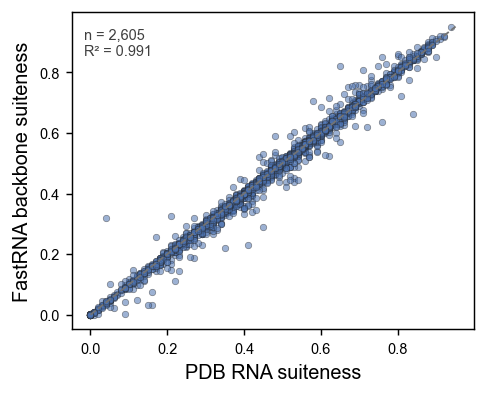

In [3]:
def draw_a(ax):
    d = STRUCT.dropna(subset=["rnasuiteness", "backbone_suiteness"])
    ax.scatter(d.rnasuiteness, d.backbone_suiteness, s=13, facecolor=BLUE,
               edgecolor=POINT_EDGE, linewidths=0.35, alpha=0.55)
    lo = min(d.rnasuiteness.min(), d.backbone_suiteness.min())
    hi = max(d.rnasuiteness.max(), d.backbone_suiteness.max())
    ax.plot([lo, hi], [lo, hi], "--", color="0.45", lw=1.0)
    r = np.corrcoef(d.rnasuiteness, d.backbone_suiteness)[0, 1]
    ax.text(0.03, 0.95, f"n = {len(d):,}\nR\u00b2 = {r**2:.3f}", transform=ax.transAxes,
            ha="left", va="top", fontsize=8, color="0.25")
    ax.set_xlabel("PDB RNA suiteness", fontsize=11)
    ax.set_ylabel("FastRNA backbone suiteness", fontsize=11)
    finish(ax)


fig, ax = plt.subplots(figsize=(3.8, 3.1))
draw_a(ax)
fig.tight_layout()
save(fig, "figures/supplemental/figS8_A_suiteness_vs_pdb.png")
plt.show()


## Panel B-C
Unassigned backbone suites versus resolution and clashscore


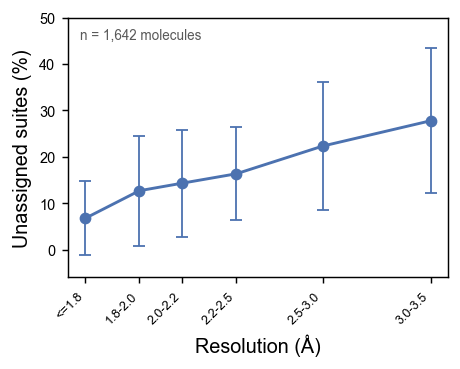

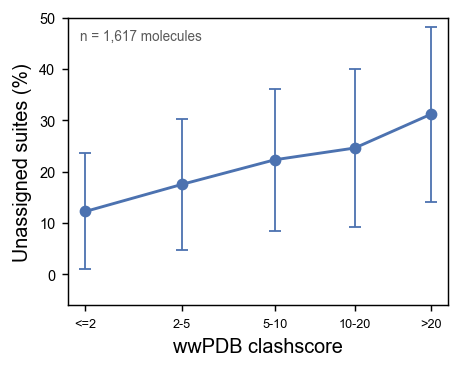

In [4]:
def draw_b(ax):
    quality_axis(ax, "resolution", "Resolution (\u00c5)", rotate=45)

def draw_c(ax):
    quality_axis(ax, "clashscore", "wwPDB clashscore", logx=True)

for fn, name in ((draw_b, "B_unassigned_vs_resolution"), (draw_c, "C_unassigned_vs_clashscore")):
    fig, ax = plt.subplots(figsize=(3.6, 2.9))
    fn(ax)
    fig.tight_layout()
    save(fig, f"figures/supplemental/figS8_{name}.png")
    plt.show()


## Panel D
Suite-conformer usage within each pair class, grouped by ribose pucker


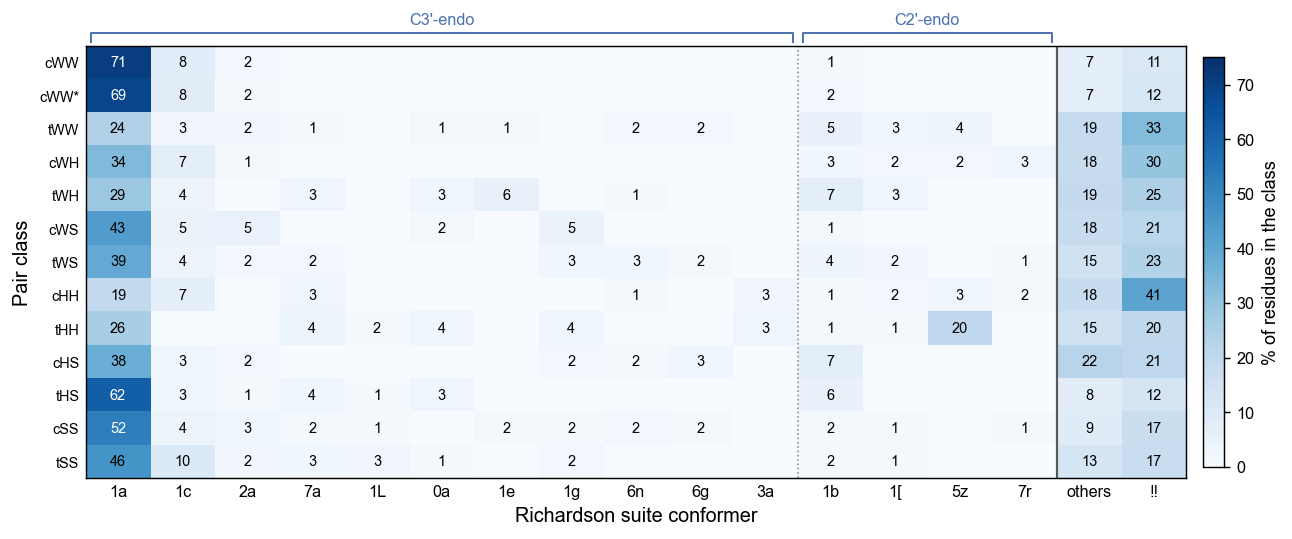

In [5]:
PUCK = conformer_pucker(RES)
_bad = {c: (PUCK[c], pucker_from_name(c)) for c in PUCK
        if pucker_from_name(c) != "neither" and PUCK[c] != pucker_from_name(c)}
assert not _bad, f"delta disagrees with the published name for: {_bad}"
USE, COLS = conformer_matrix(RES, LWROWS)

def draw_d(ax, cbar=True):
    shown = USE.apply(whole_percent, axis=1)
    vtop = 5 * np.ceil(np.nanmax(USE.values) / 5)
    im = ax.imshow(USE.values, cmap="Blues", vmin=0, vmax=vtop, aspect="auto")
    ax.set_xticks(range(USE.shape[1])); ax.set_xticklabels(USE.columns, fontsize=9)
    ax.set_yticks(range(USE.shape[0])); ax.set_yticklabels(USE.index, fontsize=8)
    ax.set_xlabel("Richardson suite conformer", fontsize=11)
    ax.set_ylabel("Pair class", fontsize=11)
    for i in range(USE.shape[0]):
        for j in range(USE.shape[1]):
            n = shown.values[i, j]
            if n >= 1:
                ax.text(j, i, str(n), ha="center", va="center", fontsize=8,
                        color="white" if USE.values[i, j] > 0.62 * vtop else "black")
    ax.axvline(len(COLS) - 0.5, color="0.35", lw=1.2)
    spans, start = [], 0
    for k in range(1, len(COLS) + 1):
        if k == len(COLS) or PUCK.get(COLS[k]) != PUCK.get(COLS[start]):
            grp = PUCK.get(COLS[start])
            if grp in ("C3'-endo", "C2'-endo"):
                spans.append((grp, start, k - 1,
                              BLUE))
            start = k
    pucker_bracket(ax, spans)
    ax.axvline(spans[0][2] + 0.5, color="0.55", lw=0.9, ls=":")
    ax.tick_params(length=0)
    if cbar:
        cb = ax.figure.colorbar(im, ax=ax, fraction=0.018, pad=0.015)
        cb.set_label("% of residues in the class", fontsize=10)
        cb.ax.tick_params(labelsize=9)
        cb.outline.set_linewidth(0.8)
    return im


fig, ax = plt.subplots(figsize=(10.0, 4.2))
draw_d(ax)
fig.tight_layout()
save(fig, "figures/supplemental/figS8_D_conformer_usage.png")
plt.show()


## Panel E
Unassignable rate within each sugar pucker, same rows as D


           C3'-endo  C2'-endo  ratio
row_class                           
cWW             9.9      34.0    3.4
cWW*           11.1      32.0    2.9
tWW            24.9      44.9    1.8
cWH            20.9      45.6    2.2
tWH            18.9      37.0    2.0
cWS            17.0      43.4    2.5
tWS            17.0      41.1    2.4
cHH            31.6      54.6    1.7
tHH             8.4      33.0    3.9
cHS            13.7      38.3    2.8
tHS             9.9      28.9    2.9
cSS            14.2      35.5    2.5
tSS            13.7      43.3    3.2


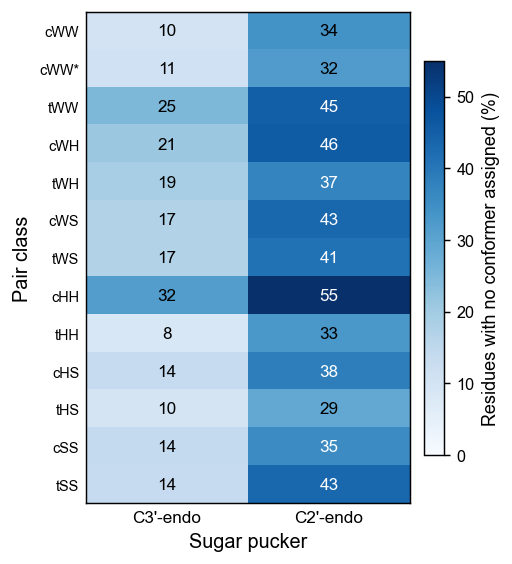

In [6]:
def _pucker_rate():
    d = RES.copy()
    dl = d.delta % 360
    d["pucker"] = np.where(dl.between(60, 105), "C3",
                           np.where(dl.between(125, 165), "C2", "btw"))
    rate = d.groupby(["row_class", "pucker"]).is_outlier.mean().unstack() * 100
    return pd.DataFrame({"C3'-endo": rate["C3"], "C2'-endo": rate["C2"]}).reindex(LWROWS)

E_MAT = _pucker_rate()
print((E_MAT.assign(ratio=(E_MAT["C2'-endo"] / E_MAT["C3'-endo"]).round(1))
       .round(1).to_string()))

def draw_e(ax, cbar=True):
    vtop = 5 * np.ceil(np.nanmax(E_MAT.values) / 5)
    im = ax.imshow(E_MAT.values, cmap="Blues", vmin=0, vmax=vtop, aspect="auto")
    ax.set_xticks([0, 1]); ax.set_xticklabels(E_MAT.columns, fontsize=9.5)
    ax.set_xlim(-0.5, 1.5)
    ax.set_xlabel("Sugar pucker", fontsize=11)
    ax.set_ylabel("Pair class", fontsize=11)
    ax.set_yticks(range(len(E_MAT))); ax.set_yticklabels(E_MAT.index, fontsize=8)
    for i in range(E_MAT.shape[0]):
        for j in range(E_MAT.shape[1]):
            v = E_MAT.values[i, j]
            ax.text(j, i, f"{v:.0f}", ha="center", va="center", fontsize=9.5,
                    color="white" if v > 0.62 * vtop else "black")
    ax.tick_params(length=0)
    if cbar:
        cb = ax.figure.colorbar(im, ax=ax, fraction=0.055, pad=0.04)
        cb.set_label("Residues with no conformer assigned (%)", fontsize=10)
        cb.ax.tick_params(labelsize=9)
        cb.outline.set_linewidth(0.8)
    return im


fig, ax = plt.subplots(figsize=(4.0, 4.4))
draw_e(ax)
fig.tight_layout()
save(fig, "figures/supplemental/figS8_E_unassigned_by_pucker.png")
plt.show()


## Combined figure


text scaled x1.81: 7 pt prints at 7.1 pt at page width


axis titles print at 8.5 pt and panel letters at 12.0 pt (12.18 in saved, shown at 6.73 in)


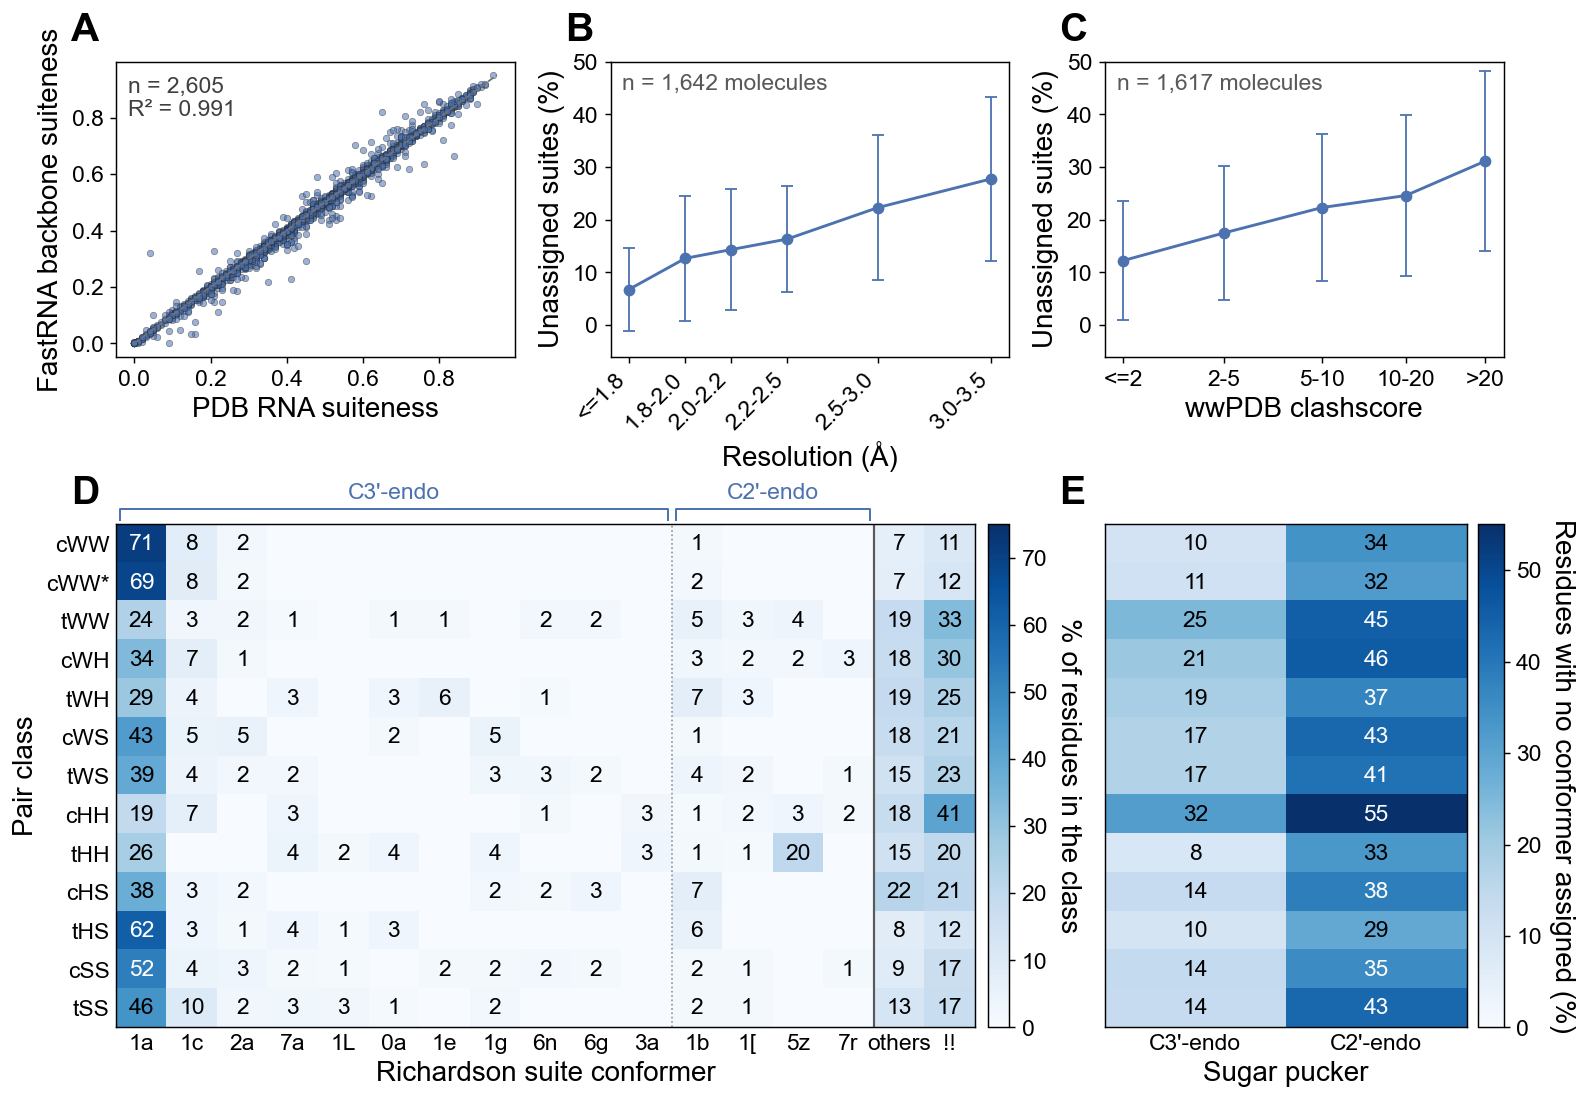

In [7]:
fig = plt.figure(figsize=(11.6, 8.3))
gs = fig.add_gridspec(2, 3, height_ratios=[0.95, 1.62], wspace=0.24, hspace=0.42,
                      left=0.065, right=0.985, top=0.965, bottom=0.07)
ax_a = fig.add_subplot(gs[0, 0]); ax_b = fig.add_subplot(gs[0, 1]); ax_c = fig.add_subplot(gs[0, 2])
sub_d = gs[1, :2].subgridspec(1, 2, width_ratios=[1.0, 0.025], wspace=0.03)
sub_e = gs[1, 2].subgridspec(1, 2, width_ratios=[1.0, 0.07], wspace=0.06)
ax_d, cax_d = fig.add_subplot(sub_d[0, 0]), fig.add_subplot(sub_d[0, 1])
ax_e, cax_e = fig.add_subplot(sub_e[0, 0]), fig.add_subplot(sub_e[0, 1])
draw_a(ax_a); draw_b(ax_b); draw_c(ax_c)
for ax, cax, draw, label in ((ax_d, cax_d, draw_d, "% of residues in the class"),
                             (ax_e, cax_e, draw_e, "Residues with no conformer assigned (%)")):
    cb = fig.colorbar(draw(ax, cbar=False), cax=cax)
    cb.set_label(label, rotation=270, va="bottom")
    cb.outline.set_linewidth(0.8)
ax_e.set_yticklabels([])
ax_e.set_ylabel("")
for ax, s in ((ax_a, "A"), (ax_b, "B"), (ax_c, "C"), (ax_d, "D")):
    letter(fig, ax, s)
letter(fig, ax_e, "E")
import matplotlib.text as mtext
for _t in fig.findobj(mtext.Text):
    if _t in fig.texts and _t.get_fontweight() in ("bold", 700) and len(_t.get_text().strip()) <= 2:
        _t.set_fontsize(12)
    else:
        _t.set_fontsize(7)
enlarge_axis_labels(fig)
for _ax in fig.axes:
    _ax.xaxis.label.set_fontsize(7)
    _ax.yaxis.label.set_fontsize(7)
import matplotlib.text as _mtext
def _print_scale(fig, page_in=6.73, pad=0.08):
    fig.canvas.draw()
    bb = fig.get_tightbbox(fig.canvas.get_renderer())
    return max(1.0, (bb.width + 2 * pad) / page_in)
fig.canvas.draw()
_texts = [t for t in fig.findobj(_mtext.Text) if t.get_text().strip()]
_base = {t: t.get_fontsize() for t in _texts}
_s = 1.0
for _ in range(6):
    _need = _print_scale(fig)
    if _s >= _need - 1e-3:
        break
    _s = _need * 1.01
    for _t in _texts:
        _t.set_fontsize(_base[_t] * _s)
print(f"text scaled x{_s:.2f}: 7 pt prints at {7 * _s / _print_scale(fig):.1f} pt "
      f"at page width")
def _set_print_sizes(fig, axis_pt=8.5, letter_pt=12.0, page_in=6.73, pad=0.08):
    letters = [t for t in fig.texts if t.get_text().strip().isalpha()
               and t.get_text().strip().isupper() and len(t.get_text().strip()) <= 2
               and t.get_fontweight() in ("bold", 700)]
    for _ in range(8):
        fig.canvas.draw()
        bb = fig.get_tightbbox(fig.canvas.get_renderer())
        shrink = max(1.0, (bb.width + 2 * pad) / page_in)
        for ax in fig.axes:
            for lab in (ax.xaxis.label, ax.yaxis.label):
                if lab.get_text().strip():
                    lab.set_fontsize(axis_pt * shrink)
        for t in letters:
            t.set_fontsize(letter_pt * shrink)
    print(f"axis titles print at {axis_pt} pt and panel letters at {letter_pt} pt "
          f"({bb.width + 2 * pad:.2f} in saved, shown at {min(page_in, bb.width + 2 * pad):.2f} in)")


_set_print_sizes(fig)

save(fig, "figures/supplemental/figS8.png")
plt.show()
